DAY 01 – DRUG DISCOVERY RESEARCH

Project:
Quantum AI for Drug Discovery

Research Objective:
To understand molecular structures and
calculate basic molecular properties using Python.

Research Questions:

1. What is a molecule?
2. What is a drug candidate?
3. What is a SMILES notation?
4. What is molecular weight?
5. How can Python analyze molecules?

Tools:
Python
RDKit
Google Colab

Expected Outcome:
Build a basic molecular analysis system.

In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 55.7 MB/s  0:00:00


In [ ]:
import rdkit

print("RDKit Version:", rdkit.__version__)

print("Drug Discovery Environment Ready!")

RDKit Version: 2026.09.1
Drug Discovery Environment Ready!


CCO

In [ ]:
from rdkit import Chem

smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

print("Molecule created:", mol is not None)

print("Canonical SMILES:",
      Chem.MolToSmiles(mol))

print("Number of atoms:",
      mol.GetNumAtoms())

print("Number of bonds:",
      mol.GetNumBonds())

Molecule created: True
Canonical SMILES: CCO
Number of atoms: 3
Number of bonds: 2


In [ ]:
from rdkit.Chem import Descriptors
from rdkit.Chem import Lipinski

print("Molecular Weight:",
      Descriptors.MolWt(mol))

print("LogP:",
      Descriptors.MolLogP(mol))

print("TPSA:",
      Descriptors.TPSA(mol))

print("HBD:",
      Lipinski.NumHDonors(mol))

print("HBA:",
      Lipinski.NumHAcceptors(mol))

Molecular Weight: 46.069
LogP: -0.0014000000000000123
TPSA: 20.23
HBD: 1
HBA: 1


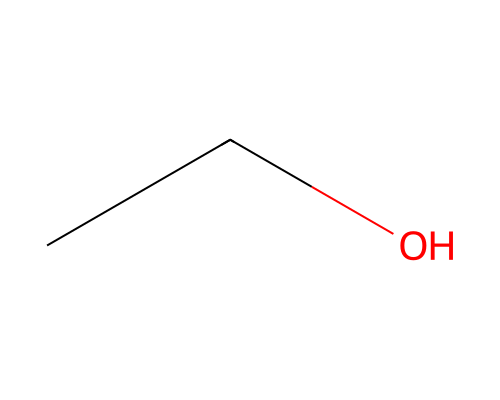

In [ ]:
from rdkit.Chem import Draw

image = Draw.MolToImage(mol, size=(500, 400))

display(image)

In [ ]:
import pandas as pd

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

molecules = {
    "Ethanol": "CCO",
    "Water": "O",
    "Aspirin": "CC(=O)OC1=CC=CC=C1C(=O)O",
    "Caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "Glucose": "C(C1C(C(C(C(O1)O)O)O)O)O"
}

results = []

for name, smiles in molecules.items():

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        continue

    results.append({
        "Name": name,
        "SMILES": Chem.MolToSmiles(mol),
        "Molecular_Weight": round(
            Descriptors.MolWt(mol), 2),
        "LogP": round(
            Descriptors.MolLogP(mol), 3),
        "TPSA": round(
            Descriptors.TPSA(mol), 2),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol)
    })

df = pd.DataFrame(results)

display(df)

,Name,SMILES,Molecular_Weight,LogP,TPSA,HBD,HBA
0,Ethanol,CCO,46.07,-0.001,20.23,1,1
1,Water,O,18.02,-0.825,31.50,0,0
2,Aspirin,CC(=O)Oc1ccccc1C(=O)O,180.16,1.310,63.60,1,3
3,Caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O,194.19,-1.029,61.82,0,3
4,Glucose,OCC1OC(O)C(O)C(O)C1O,180.16,-3.221,110.38,5,6


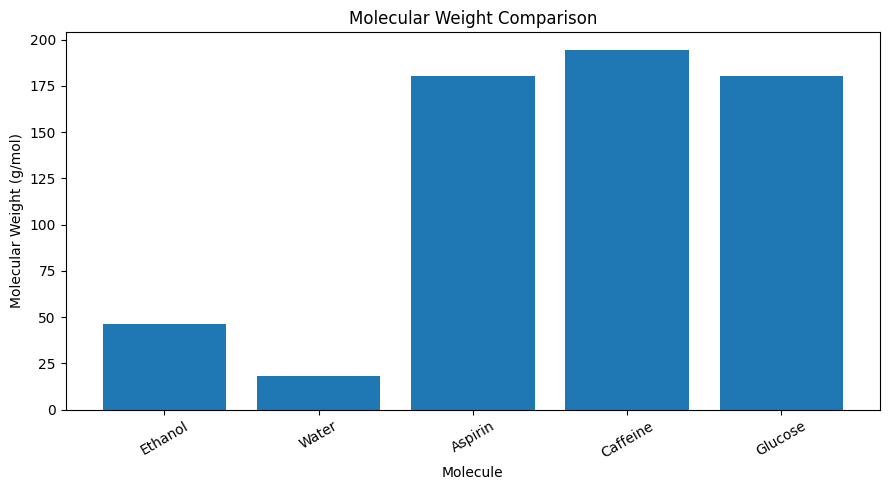

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    df["Name"],
    df["Molecular_Weight"]
)

plt.title("Molecular Weight Comparison")

plt.xlabel("Molecule")

plt.ylabel("Molecular Weight (g/mol)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [ ]:
df.to_csv(
    "Day01_Drug_Molecular_Analysis.csv",
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!


In [ ]:
from google.colab import files

files.download(
    "Day01_Drug_Molecular_Analysis.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1\. What is a molecule?\
A molecule is a group of two or more atoms chemically bonded together.

2\. What is SMILES?\
SMILES is a text format used to represent the chemical structure of a molecule.

3\. What is molecular weight?\
Molecular weight is the total mass of all atoms in a molecule.

4\. Why is LogP important?\
LogP tells us how well a molecule prefers fat or water. It helps predict drug absorption and solubility.

5\. Can molecular weight alone identify a good drug candidate?\
No. A good drug candidate depends on several properties, such as molecular weight, LogP, solubility, and toxicity.